# CENG468 Veri Madenciliği · Hafta 5
## ⭐ Ek alıştırmalar (E1–E8): çözümler ve açıklamalar
Öğr. Gör. Dr. Duygu TOPALOĞLU · 2026-2027 Güz

---
### Bu defter nasıl kullanılır?
Bu defter, Hafta 5 defterinin (*CENG468_H05_Ilk_Oneri*) sonundaki **⭐ ek alıştırmaların** çözümlerini içerir. Derste bu alıştırmalara zaman kalmadı; bu defteri **kendi başına** inceleyeceksin.

**Önerilen sıra:**
1. Önce **Hazırlık** bölümünü oku: veriyi tanımadan temizlik kararlarının nedenini anlayamayız.
2. Alıştırmayı Hafta 5 defterinde **kendin dene**. Cevabını tahmin et, kodu yaz, çalıştır.
3. Sonra buradaki çözümle karşılaştır. Kodun farklıysa sorun değil; **aynı sonuca** ulaşıyor mu, ona bak.
4. Her çözümün altındaki açıklamaları mutlaka oku. Asıl öğrenilecek şey kod değil, sonucun **ne anlattığı** ve o sonuca **nasıl varıldığı**.

**Her alıştırmada aynı düzen var:**

| Kısım | Ne var? |
|---|---|
| **Soru** | Hafta 5 defterindeki sorunun aynısı |
| **Çözüm** | Çalışan kod |
| **Kod ne yapıyor?** | Kodun parça parça açıklaması |
| **Sonucu nasıl okumalı?** | Çıktının veri hakkında söyledikleri |
| **🔁 Benzerini dene** | Aynı kalıpla çözülen küçük bir soru. Cevabı kapalı kutuda; önce kendin yaz. |

**Renkli kutuların anlamı:**

<table>
<tr><td style="background:#e8f5e9; color:#1a1a1a; border-left:6px solid #2e7d32"><b>🎯 Ne elde ettik?</b></td><td>Bu adımdan çıkan sonuç. Not alacağın yer burası.</td></tr>
<tr><td style="background:#e3f2fd; color:#1a1a1a; border-left:6px solid #1565c0"><b>🔍 Buna nasıl vardık?</b></td><td>Sonuca hangi ipuçlarıyla, hangi sırayla ulaştığımız.</td></tr>
<tr><td style="background:#fff3e0; color:#1a1a1a; border-left:6px solid #ef6c00"><b>⚠️ Dikkat</b></td><td>Kolayca gözden kaçan bir tuzak ya da bir yöntemin sınırı.</td></tr>
<tr><td style="background:#ffebee; color:#1a1a1a; border-left:6px solid #c62828"><b>📌 Asıl ders</b></td><td>Alıştırmanın dersin geneline bağlanan ana fikri.</td></tr>
<tr><td style="background:#f3e5f5; color:#1a1a1a; border-left:6px solid #6a1b9a"><b>🧭 Karar senin</b></td><td>Verinin cevaplamadığı, analistin vermesi gereken bir karar.</td></tr>
</table>

> Bu defter **kendi başına çalışır**: veriyi kendisi okur ve Bölüm 3'teki temizliği kendi içinde yeniden yapar. Hafta 5 defterini sonuna kadar çalıştırmamış olsan da sorun olmaz. Hücreleri **yukarıdan aşağıya sırayla** çalıştır.

---
## Hazırlık A: Veriyi oku
Hafta 5 defterindeki ilk hücrenin aynısı. CSV kopyası varsa birkaç saniyede, yoksa Excel'den 30–90 saniyede okunur. Grafikler için `matplotlib`'i de yüklüyoruz.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

VERI = "Veri/online_retail"
XLSX = os.path.join(VERI, "online_retail_II.xlsx")
CSV = os.path.join(VERI, "online_retail_2010_2011.csv")

if os.path.exists(CSV):
    df = pd.read_csv(CSV, dtype={"Invoice": str, "StockCode": str},
                     parse_dates=["InvoiceDate"])
    print("Hızlı yol: CSV okundu.")
elif os.path.exists(XLSX):
    df = pd.read_excel(XLSX, sheet_name="Year 2010-2011",
                       dtype={"Invoice": str, "StockCode": str})
    df.to_csv(CSV, index=False)
    print("İlk açılış: Excel okundu ve CSV olarak kaydedildi.")
else:
    raise FileNotFoundError(
        "Veri dosyası bulunamadı: " + os.path.abspath(XLSX)
        + "\nVeri/online_retail/BENIOKU.md dosyasındaki adımları izle.")

# Grafikler için ortak renkler: satış yeşil, iptal kırmızı, diğerleri gri
YESIL, KIRMIZI, MAVI, GRI, TURUNCU = "#2e7d32", "#c62828", "#1565c0", "#9e9e9e", "#ef6c00"

print("Satır, sütun:", df.shape)

Hızlı yol: CSV okundu.
Satır, sütun: (541910, 8)


---
## Hazırlık B: Temizlemeden önce veriyi tanı
Hafta 5'te bazı satırları "tuhaf" bulup sildik. Ama **neden** tuhaf olduklarını söyleyebilmek için önce **normal** bir satırın nasıl göründüğünü bilmek gerekir. Bu bölümde dört soruya cevap arıyoruz:

1. Her sütun ne anlatıyor?
2. Bir satır neyi, bir fatura neyi temsil ediyor?
3. `C` ve `A` ile başlayan faturalar ne?
4. Ürün kodları neye benziyor, hangi kodlar ürün değil?

### B1. Sütun sözlüğü
Bir veri setiyle karşılaştığında ilk iş, **veriyi yayımlayanın açıklamasını** okumaktır. Online Retail II'nin açıklaması UCI Machine Learning Repository sayfasında. Özetle:

| Sütun | Resmî açıklama (özet) | Bizim için anlamı |
|---|---|---|
| `Invoice` | 6 haneli fatura numarası. **`c` ile başlıyorsa iptal** demektir. | Bir **sepet**. Aynı numaralı satırlar aynı alışverişe ait. |
| `StockCode` | 5 haneli ürün kodu, her ürüne ayrı. | Ürünün kimliği. 5 rakama uymayanlar şüpheli. |
| `Description` | Ürünün adı. | Kod tuhafsa bakacağımız ilk yer. |
| `Quantity` | O satırdaki ürün adedi. | Eksi değer = iade ya da düzeltme. |
| `InvoiceDate` | Faturanın tarihi ve saati. | Aynı faturanın bütün satırlarında aynı. |
| `Price` | Birim fiyat (sterlin, £). | Satır tutarı = `Quantity × Price`. |
| `Customer ID` | 5 haneli müşteri numarası. | Boşsa kimin aldığını bilmiyoruz. |
| `Country` | Müşterinin ülkesi. | |

Açıklamada **`A` ile başlayan faturalardan hiç söz edilmiyor.** Onların ne olduğunu verinin kendisinden çıkaracağız (B3).

### B2. Bir satır mı, bir fatura mı?
Verideki ilk faturaya bakalım:

In [2]:
df[df["Invoice"] == "536365"]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom


Yedi satırın hepsinde fatura numarası, tarih-saat, müşteri ve ülke **aynı**; değişen yalnızca ürün, adet ve fiyat. Yani bu yedi satır **tek bir alışveriş**.

<div style="background:#e8f5e9; color:#1a1a1a; border-left:6px solid #2e7d32; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#2e7d32; font-size:1.05em">🎯 Ne elde ettik?</b>

- **Bir satır = sepetteki bir ürün kalemi.** **Bir fatura = bir sepet.**
- Bu yüzden "Almanya'dan 9.495 satır" demek "9.495 alışveriş" demek değildir (E1).
- Sepet analizi (gelecek hafta) faturayı birim olarak alır: "aynı faturada hangi ürünler birlikte geçiyor?"

</div>

### B3. Fatura numarasının ilk karakteri
Normal bir fatura numarası 6 rakamdan oluşur. İlk karaktere göre sayalım:

Invoice
rakam    532619
C          9288
A             3
Name: count, dtype: int64


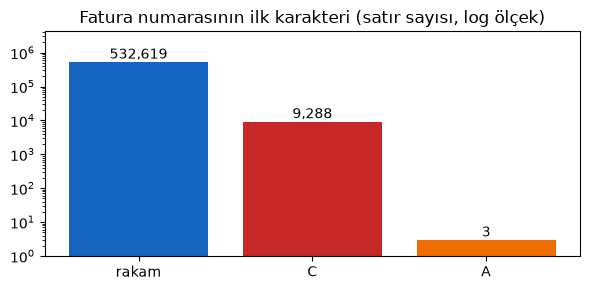

In [3]:
ilk_karakter = df["Invoice"].str[0].map(lambda k: k if not k.isdigit() else "rakam")
sayim = ilk_karakter.value_counts()
print(sayim)

# Grafik: dikey eksen logaritmik; yoksa 3 satırlık 'A' hiç görünmezdi.
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(sayim.index, sayim.values, color=[MAVI, KIRMIZI, TURUNCU])
ax.set_yscale("log")
ax.set_ylim(1, sayim.max() * 8)   # sayı etiketleri başlığa çarpmasın
ax.set_title("Fatura numarasının ilk karakteri (satır sayısı, log ölçek)")
for i, v in enumerate(sayim.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

Üç grup var: rakamla başlayanlar (normal faturalar), `C` ile başlayanlar ve yalnızca **3 satırlık** `A` grubu. Grafikte dikey ekseni **logaritmik** yaptık: her çizgi bir öncekinin 10 katı. Düz eksende 3 satırlık `A` çubuğu sıfırdan ayırt edilemezdi.

**`C` faturaları:** Resmî açıklama "iptal" diyor. Ama açıklamaya körü körüne güvenmek yerine **veride doğrulayalım**: Bir iptal faturasında adetler eksi olmalı.

In [4]:
iptal_satirlar = df[df["Invoice"].str.startswith("C")]
print("İptal satırı sayısı        :", len(iptal_satirlar))
print("Farklı iptal faturası      :", iptal_satirlar["Invoice"].nunique())
print("Adedi artı olan iptal satırı:", (iptal_satirlar["Quantity"] > 0).sum())

İptal satırı sayısı        : 9288
Farklı iptal faturası      : 3836
Adedi artı olan iptal satırı: 0


Adedi artı olan **hiçbir** iptal satırı yok. Açıklama ile veri aynı şeyi söylüyor.

**`A` faturaları:** Açıklamada yoklar. O zaman tek yol, satırların kendisine bakmak:

In [5]:
df[df["Invoice"].str.startswith("A")]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
299982,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


Üç satırın açıklaması **"Adjust bad debt"**: muhasebede *şüpheli alacak düzeltmesi*. Tahsil edilemeyen bir borcun kayıtlardan düşülmesi. Ürün kodu `B`, müşteri yok, tutar yaklaşık 11 bin sterlin ve iki satırda **fiyat eksi**. Hafta 5'te `df[df["Price"] < 0]` ile bulduğumuz eksi fiyatlı satırlar bunlardı.

<div style="background:#e3f2fd; color:#1a1a1a; border-left:6px solid #1565c0; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#1565c0; font-size:1.05em">🔍 Buna nasıl vardık?</b>

1. **Önce belgeye baktık:** `C` resmî açıklamada var.
2. **Belgeyi veride sınadık:** İptal satırlarının hepsinde adet eksi. Belge ile veri tutarlı.
3. **Belgede olmayanı veriden çıkardık:** `A` hiçbir yerde açıklanmamış. Satırları açıp `Description` sütununu **okuduk**.

Bu sıra her yeni veri setinde işe yarar: *belge → veride sınama → belgede olmayanı satırları okuyarak anlama.*

</div>

### B4. Ürün kodları neye benziyor?
Açıklamaya göre ürün kodu "5 haneli bir sayı". Bunu **sınayalım**. Ama nasıl? Desenin ne olduğunu bilmiyoruz; onu verinin kendisinden bulmamız gerekiyor. Dört adımda ilerleyeceğiz.

**Adım 1: Birkaç örneğe bak.** İlk akla gelen, rastgele birkaç koda göz atmak:

In [6]:
df["StockCode"].sample(12, random_state=1).tolist()

['22960',
 '23171',
 '22326',
 '22132',
 '22197',
 '22382',
 '22737',
 '22268',
 '22666',
 '23297',
 '22795',
 '21212']

On iki kodun hepsi 5 rakam. "Açıklama doğruymuş" deyip geçebilirdik. Ama dikkat: **rastgele örnek nadir durumları göstermez.** Tuhaf kodlar azsa, 12 örnekte hiç çıkmayabilir. Bütün sütuna bakan bir yönteme ihtiyacımız var.

**Adım 2: Uzunluklara bak.** Her kodun kaç karakter olduğunu sayalım. Hepsi 5 haneliyse tek bir satır görmeliyiz:

In [7]:
df["StockCode"].str.len().value_counts().sort_index()

StockCode
1        715
2        144
3        710
4       1277
5     487036
6      51488
7        390
8         31
9         48
12        71
Name: count, dtype: int64

5 karakterli kodlar çoğunlukta, ama **1'den 12'ye kadar** başka uzunluklar da var. İlk ipucu bu: kodların hepsi 5 haneli değil. Ama uzunluk tek başına yetmiyor: 6 karakterli bir kod `851232` gibi bir sayı da olabilir, `85123A` gibi harfli bir kod da.

**Adım 3: Desen maskesi çıkar.** Her kodun **içeriğini değil, biçimini** görmek istiyoruz. Bunun için her rakamı `9` ile, her harfi `A` ile değiştiririz. Böylece `85123A` → `99999A`, `POST` → `AAAA` olur. Sonra bu desenleri sayarız:

In [8]:
desen = (df["StockCode"]
         .str.replace(r"[0-9]", "9", regex=True)      # her rakam → 9
         .str.replace(r"[A-Za-z]", "A", regex=True))  # her harf  → A
desen.value_counts()

StockCode
99999           487036
99999A           51488
AAAA              1277
A                  715
AAA                710
99999AA            390
A9                 144
AAAAAAAAA           47
AAAA AAAAAAA        37
AAAA_9999_99        34
AAAA9999            20
AAAAAAAA            11
AAAA9999A            1
Name: count, dtype: int64

Şimdi yapı açıkça görünüyor:
- `99999`: Açıklamadaki "5 haneli sayı". Büyük çoğunluk.
- `99999A`, `99999AA`: 5 rakam ve **arkasından harf**. Yaklaşık 52 bin satır; ayrı bir grup.
- `A`, `AAA`, `AAAA`, `A9`, `AAAA_9999_99`…: **Harfle başlayan**, birbirine benzemeyen birçok küçük desen.

Bu tabloya bakınca kodları **üç gruba** ayırmak doğal bir karar oluyor: *5 rakam*, *5 rakam + harf* ve *harfle başlayanlar*. Grupları biz uydurmadık; **desen tablosundan okuduk.**

<div style="background:#e3f2fd; color:#1a1a1a; border-left:6px solid #1565c0; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#1565c0; font-size:1.05em">🔍 Buna nasıl vardık?</b>

| Adım | Ne yaptık? | Ne öğrendik? |
|---|---|---|
| 1 | `sample()` ile birkaç örneğe baktık | Hepsi normal göründü. **Yanıltıcı:** nadir durumlar örnekte çıkmaz. |
| 2 | `str.len().value_counts()` | Kodların hepsi 5 karakter değil. |
| 3 | Rakam → `9`, harf → `A`, sonra `value_counts()` | Kodların **biçimleri** ve her biçimin kaç satırda geçtiği. |
| 4 | Her desenden örnek okuyacağız (aşağıda) | Desenin **anlamı**. |

Desen maskesi her türlü kod sütununda işe yarar: fatura numarası, posta kodu, telefon, plaka. Yeni bir veride bir kod sütunu gördüğünde **ilk denemen gereken şeylerden biri** bu.

</div>

**Adım 4: Grupları say ve anlamlarına bak.** Desen tablosundan çıkardığımız üç grubu kodla tanımlayalım:

5 rakam (ör. 71053)            487036
5 rakam + harf (ör. 85123A)     51878
harfle başlıyor                  2996
Name: count, dtype: int64


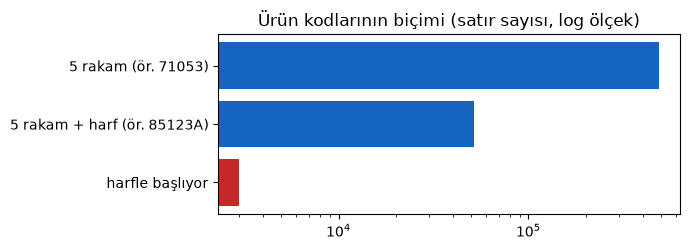

In [9]:
kod = df["StockCode"]
bicim = pd.Series("harfle başlıyor", index=df.index)
bicim[kod.str.fullmatch(r"\d{5}[A-Za-z]+")] = "5 rakam + harf (ör. 85123A)"
bicim[kod.str.fullmatch(r"\d{5}")] = "5 rakam (ör. 71053)"
bicim_sayim = bicim.value_counts()
print(bicim_sayim)

fig, ax = plt.subplots(figsize=(7, 2.6))
ax.barh(bicim_sayim.index[::-1], bicim_sayim.values[::-1], color=[KIRMIZI, MAVI, MAVI])
ax.set_xscale("log")
ax.set_title("Ürün kodlarının biçimi (satır sayısı, log ölçek)")
plt.tight_layout()
plt.show()

`5 rakam + harf` biçimi aynı ürünün **çeşitleri** (renk, boyut): `85123A` ve `85123B` gibi. Bunlar gerçek ürün. **Harfle başlayan** yaklaşık 3 bin satır ise ayrı bir grup. Bu kodların her birinin açıklamasına, kaç satırda geçtiğine ve tipik fiyatına bakalım:

In [10]:
harfli = df[~df["StockCode"].str[0].str.isdigit()]
harfli.groupby("StockCode").agg(
    aciklama=("Description", "first"),
    satir=("Invoice", "size"),
    medyan_fiyat=("Price", "median"),
).sort_values("satir", ascending=False).head(12)

,aciklama,satir,medyan_fiyat
StockCode,,,
POST,POSTAGE,1257,18.000
DOT,DOTCOM POSTAGE,710,184.940
M,Manual,571,7.950
C2,CARRIAGE,144,50.000
D,Discount,77,22.970
S,SAMPLES,63,19.500
BANK CHARGES,Bank Charges,37,82.730
AMAZONFEE,AMAZON FEE,34,5909.875
CRUK,CRUK Commission,16,471.770


Açıklamaları okuyunca tablo kendini anlatıyor: **POSTAGE** ve **CARRIAGE** (kargo), **Manual** (elle düzeltme), **Discount** (indirim), **Bank Charges** (banka masrafı), **AMAZON FEE** (Amazon komisyonu), **CRUK Commission** (bağış komisyonu). Bunlar **hizmet ve muhasebe kalemleri**; rafta duran, müşteriye önerilebilecek ürünler değil.

<div style="background:#fff3e0; color:#1a1a1a; border-left:6px solid #ef6c00; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#ef6c00; font-size:1.05em">⚠️ Dikkat</b>

Kuralımız "**rakamla başlamayan kodu sil**". Kural çoğunlukla doğru çalışıyor, ama kusursuz değil. Tablonun aşağılarına inersen `DCGSSGIRL` (*GIRLS PARTY BAG*), `gift_0001_20` (*hediye çeki*), `PADS` gibi **gerçek ürünler** de görürsün. Bunlar yaklaşık 80 satır; kuralımız bunları da siliyor.

Neredeyse her temizlik kuralının böyle küçük bir yan etkisi vardır. Önemli olan, yan etkiyi **bilerek** kabul etmek: 530 bin satırın içinde 80 satırı kaybetmek, kargo ve komisyon satırlarını ürün sanmaktan daha az zararlı.

</div>

### B5. Özet: hangi satırı neden siliyoruz?
Artık Hafta 5'teki altı temizlik kararının her birinin **veriden bir kanıtı** var:

<table>
<tr style="background:#37474f; color:#ffffff"><th>Karar</th><th>Neden?</th><th>Kanıt nerede?</th></tr>
<tr style="background:#ffebee; color:#1a1a1a"><td><b>1. <code>C</code> faturalarını sil</b></td><td>Satış değil, iptal. Adetlerin hepsi eksi.</td><td>B3</td></tr>
<tr style="background:#ffebee; color:#1a1a1a"><td><b>2. <code>A</code> faturalarını sil</b></td><td>Satış değil, şüpheli alacak düzeltmesi (muhasebe kaydı).</td><td>B3</td></tr>
<tr style="background:#fff3e0; color:#1a1a1a"><td><b>3. Adet ≤ 0 olanları sil</b></td><td>İptal olmadığı hâlde eksi adetli satırlar: büyük olasılıkla stok düzeltmeleri.</td><td>H05 Bölüm 2.2, E3</td></tr>
<tr style="background:#fff3e0; color:#1a1a1a"><td><b>4. Fiyat ≤ 0 olanları sil</b></td><td>Sıfır fiyatlı satır satış değildir. Açıklaması boş satırların hepsi bu grupta.</td><td>H05 Bölüm 2.3, E3</td></tr>
<tr style="background:#e3f2fd; color:#1a1a1a"><td><b>5. Ürün dışı kodları sil</b></td><td>Kargo, komisyon, indirim, banka masrafı: öneri listesine girmemeli.</td><td>B4, E2</td></tr>
<tr style="background:#e3f2fd; color:#1a1a1a"><td><b>6. Tekrarlı satırları sil</b></td><td>Bütün sütunları aynı olan satırlar büyük olasılıkla kayıt tekrarı.</td><td>H05 Bölüm 2.5</td></tr>
</table>

<div style="background:#e8f5e9; color:#1a1a1a; border-left:6px solid #2e7d32; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#2e7d32; font-size:1.05em">🎯 Ne elde ettik?</b>

"**Bu satırı neden sildin?**" sorusuna artık "tuhaf görünüyordu" diye değil, "**veride şunu gördüm**" diye cevap verebiliyoruz. İyi bir temizliği, kararların her birinin bir kanıtı olması ayırt eder.

</div>

---
## Hazırlık C: Temizle (Bölüm 3'teki sınıf kararları)
E4–E8 temizlenmiş tabloyla (`df_temiz`) çalışıyor. Aşağıdaki hücre yukarıdaki altı kararı sırayla uygular. Her satır bir **maske**: tutmak istediğimiz satırlar `True`.

Ham tablo `df` olduğu gibi kalır; E1–E3 ham tabloyla çalışıyor.

In [11]:
def adim(veri, maske, aciklama):
    """Maskesi True olan satırları tutar; kaç satır çıktığını yazar."""
    sonra = veri[maske]
    print(f"{aciklama:<30} çıkan: {len(veri) - len(sonra):>7,}   kalan: {len(sonra):>7,}")
    return sonra


d = df.copy()
d = adim(d, ~d["Invoice"].str.startswith("C"), "İptal faturalar")
d = adim(d, ~d["Invoice"].str.startswith("A"), "'A' faturalar")
d = adim(d, d["Quantity"] > 0, "Adet sıfır ya da eksi")
d = adim(d, d["Price"] > 0, "Fiyat sıfır ya da eksi")
d = adim(d, d["StockCode"].str[0].str.isdigit(), "Ürün dışı kodlar")
d = adim(d, ~d.duplicated(), "Tekrarlı satırlar")
df_temiz = d
print(f"\nTemiz tablo: {len(df_temiz):,} satır")

İptal faturalar                çıkan:   9,288   kalan: 532,622
'A' faturalar                  çıkan:       3   kalan: 532,619
Adet sıfır ya da eksi          çıkan:   1,336   kalan: 531,283
Fiyat sıfır ya da eksi         çıkan:   1,179   kalan: 530,104


Ürün dışı kodlar               çıkan:   2,379   kalan: 527,725


Tekrarlı satırlar              çıkan:   5,221   kalan: 522,504

Temiz tablo: 522,504 satır


---
## Bölüm 1'in ek alıştırmaları (ham veri: `df`)

### ⭐ E1
**Soru:** Almanya'dan kaç satır var? (Yukarıdaki `ulkeler` işini görür.)

In [12]:
ulkeler = df["Country"].value_counts()
print(ulkeler["Germany"])

9495


**Kod ne yapıyor?**
- `df["Country"]` tek bir sütun seçer; sonuç bir **Series**.
- `.value_counts()` her ülkenin kaç satırda geçtiğini sayar ve **büyükten küçüğe** sıralar. Sonuç yine bir Series: index'te (solda) ülke adları, değerlerde (sağda) satır sayıları.
- `ulkeler["Germany"]` bu Series'ten **etiketle** okur, sözlükteki `sozluk["anahtar"]` gibi.

**Sonucu nasıl okumalı?**
Almanya'dan **9.495 satır** var. Almanya listede ikinci sırada ama İngiltere'nin (yaklaşık 495 bin satır) yanında çok küçük kalıyor.

<div style="background:#e8f5e9; color:#1a1a1a; border-left:6px solid #2e7d32; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#2e7d32; font-size:1.05em">🎯 Ne elde ettik?</b>

- 9.495 **satır** = 9.495 **ürün kalemi**; sipariş ya da müşteri sayısı değil (B2).
- Verinin **%90'dan fazlası** tek bir ülkeden geliyor. Bu dengesizlik E7'de karşımıza tekrar çıkacak.

</div>

**🔁 Benzerini dene:** Listede **ikinci ve üçüncü sıradaki** ülkeler hangileri, kaçar satırları var? (İpucu: sıraya göre okumak için `.iloc[...]` ya da `.head(...)`.)

In [13]:
# Kodunu buraya yaz

<details><summary>✅ Cevap</summary>

```python
ulkeler.iloc[1:3]
```
Almanya (9.495) ve Fransa (8.558). `.iloc` **sıra numarasıyla** okur ve saymaya 0'dan başlar: `1:3` ikinci ve üçüncü elemanları verir (3 dahil değil).

</details>

### ⭐ E2
**Soru:** Fiyatı (`Price`) en yüksek 3 satırı göster. Bunlar gerçekten ürün mü? `Invoice` sütununa da bak.

In [14]:
df.nlargest(3, "Price")

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
222681,C556445,M,Manual,-1,2011-06-10 15:31:00,38970.00,15098.0,United Kingdom
524602,C580605,AMAZONFEE,AMAZON FEE,-1,2011-12-05 11:36:00,17836.46,NaN,United Kingdom
43702,C540117,AMAZONFEE,AMAZON FEE,-1,2011-01-05 09:55:00,16888.02,NaN,United Kingdom


**Kod ne yapıyor?**
`df.nlargest(3, "Price")`, `Price` sütununa göre en büyük 3 satırı **bütün sütunlarıyla** getirir. Aynı işi `df.sort_values("Price", ascending=False).head(3)` de yapar; `nlargest` daha kısa ve hızlıdır.

**Sonucu nasıl okumalı?**
Bu üç satırın **ürün olmadığını** söyleyeceğiz. Ama önce şu soruyu soralım: **Bunu nereden bileceğiz?** Satırın üstünde "ben ürün değilim" yazmıyor. Yapacağımız şey, bu satırları **normal bir satırla karşılaştırmak**. Normal satır neye benziyor? Tipik değerlere bakalım:

In [15]:
print("Tipik (medyan) fiyat :", df["Price"].median())
print("Tipik (medyan) adet  :", df["Quantity"].median())
print("Ürün kodu 5 rakamla başlayan satırların oranı:",
      round(df["StockCode"].str[:5].str.isdigit().mean(), 3))

Tipik (medyan) fiyat : 2.08
Tipik (medyan) adet  : 3.0


Ürün kodu 5 rakamla başlayan satırların oranı: 0.994


Tipik bir satırda fiyat **2 sterlin** civarında, adet **3**, ürün kodu 5 rakam. Şimdi en pahalı üç satırı bu "normal"le **sütun sütun** karşılaştıralım:

<table>
<tr style="background:#37474f; color:#ffffff"><th>Sütun</th><th>Normal bir satırda</th><th>En pahalı 3 satırda</th><th>İşaret</th></tr>
<tr style="background:#ffebee; color:#1a1a1a"><td><code>Price</code></td><td>~2 £</td><td>17 bin – 39 bin £</td><td>🚩 Normalin binlerce katı</td></tr>
<tr style="background:#ffebee; color:#1a1a1a"><td><code>Invoice</code></td><td>6 rakam</td><td><code>C</code> ile başlıyor</td><td>🚩 İptal kaydı (B3)</td></tr>
<tr style="background:#ffebee; color:#1a1a1a"><td><code>StockCode</code></td><td>5 rakam</td><td><code>M</code>, <code>AMAZONFEE</code></td><td>🚩 Ürün kodu biçiminde değil (B4)</td></tr>
<tr style="background:#ffebee; color:#1a1a1a"><td><code>Description</code></td><td>Ürün adı (<i>WHITE METAL LANTERN</i>)</td><td><i>Manual</i>, <i>AMAZON FEE</i></td><td>🚩 Bir nesne değil, bir işlem adı</td></tr>
<tr style="background:#ffebee; color:#1a1a1a"><td><code>Quantity</code></td><td>3 civarı, artı</td><td><code>-1</code></td><td>🚩 Tek kalemlik tutar düzeltmesi</td></tr>
<tr style="background:#fff3e0; color:#1a1a1a"><td><code>Customer ID</code></td><td>Çoğunlukla dolu</td><td>İkisinde boş</td><td>⚠️ Zayıf işaret</td></tr>
</table>

<div style="background:#e3f2fd; color:#1a1a1a; border-left:6px solid #1565c0; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#1565c0; font-size:1.05em">🔍 Buna nasıl vardık?</b>

**Düşünme sırası şöyleydi:**

1. **İlk dikkat çeken:** Fiyat. 39 bin sterlinlik bir hediyelik eşya mağazası ürünü olmaz. Bu, "bu satırda bir tuhaflık var" alarmını çaldırdı.
2. **Sonra sorulan soru:** "Bu satırın **başka neresi** tuhaf?" Her sütunu normal bir satırla karşılaştırdık.
3. **Sonuç:** Tek bir işaret yetmezdi. Pahalı ama gerçek bir ürün olabilirdi. Ama **beş işaret aynı yönü gösteriyor**: iptal faturası, ürün olmayan kod, işlem adı gibi açıklama, `-1` adet. Bunlar birleşince "ürün değil, **muhasebe kaydı**" demek güvenli hâle geliyor.

Bir uç değerle karşılaştığında her seferinde aynı soruyu sor: **"Bu satırın başka neresi normalden farklı?"**

</div>

<div style="background:#e8f5e9; color:#1a1a1a; border-left:6px solid #2e7d32; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#2e7d32; font-size:1.05em">🎯 Ne elde ettik?</b>

Fiyatı en yüksek satırlar **muhasebe kayıtları**: elle düzeltme (`M`) ve Amazon komisyonu. Bunlar temizlenmezse `Price` ortalaması da, "en pahalı ürünler" listesi de anlamsız olur.

</div>

**🔁 Benzerini dene:** Fiyatı en yüksek **10** satırda kaç farklı `StockCode` var ve bunlardan kaçı rakamla başlıyor (gerçek ürün kodu)?

In [16]:
# Kodunu buraya yaz

<details><summary>✅ Cevap</summary>

```python
en_pahali = df.nlargest(10, "Price")
print(en_pahali["StockCode"].value_counts())
print(en_pahali["StockCode"].str[0].str.isdigit().sum(), "tanesi rakamla başlıyor")
```
İlk 10'un hiçbiri gerçek ürün kodu değil: `AMAZONFEE`, `M` ve `B`. `B`'yi B3'ten tanıyorsun: şüpheli alacak düzeltmesi. Açıklama sütununa bakınca hepsinin bir **işlem adı** taşıdığını görürsün.

</details>

### ⭐ E3
**Soru:** `Description` sütunu boş olan satırlarda `Price` ne oluyor? (İpucu: `df.loc[maske, "Price"].describe()`)

In [17]:
bos_aciklama = df["Description"].isnull()
print("Açıklaması boş satır sayısı:", bos_aciklama.sum())
df.loc[bos_aciklama, "Price"].describe()

Açıklaması boş satır sayısı: 1454


count    1454.0
mean        0.0
std         0.0
min         0.0
25%         0.0
50%         0.0
75%         0.0
max         0.0
Name: Price, dtype: float64

**Kod ne yapıyor?**
- `df["Description"].isnull()` bir **maske** üretir: açıklaması boş olan satırlar için `True`.
- `bos_aciklama.sum()` kaç tane `True` olduğunu sayar (`True` = 1, `False` = 0).
- `df.loc[maske, "Price"]` iki şeyi birlikte seçer: **satırlar** maskeyle, **sütun** adıyla. Sonuç yalnızca bu satırların fiyatları.
- `.describe()` bu fiyatların özet istatistiklerini verir.

**Sonucu nasıl okumalı?**
Açıklaması boş **1.454 satırın hepsinde fiyat 0**: ortalama, en küçük ve en büyük değerlerin hepsi 0. Fiyatı sıfır olan bir satır satış olamaz. Peki bu satırlar **ne**? Başka sütunlara da bakalım.

#### Müşteri numarası da boş mu? Aynı satırlar mı?
`df.loc[bos_aciklama, "Customer ID"]` yazdığımızda **aynı maskeyi** kullanıyoruz. Yani bakılan müşteri numaraları, açıklaması boş olan **aynı 1.454 satırın** müşteri numaraları. Ayrı bir eşleştirme yapmaya gerek yok: maske satırları seçiyor, sütun adı yalnızca o satırların hangi sütununa bakacağımızı söylüyor.

Yine de bunu **gözle görmek** istersek `pd.crosstab` kullanırız. İki maskeyi yan yana koyar ve her birleşimden kaç satır olduğunu sayar:

In [18]:
pd.crosstab(df["Description"].isnull(), df["Customer ID"].isnull(),
            rownames=["Açıklama boş mu?"], colnames=["Müşteri no boş mu?"])

Müşteri no boş mu?,False,True
Açıklama boş mu?,,
False,406830,133626
True,0,1454


**Tabloyu okuma:**
- Sağ alt hücre (**True / True = 1.454**): Açıklaması boş satırların **hepsinde** müşteri numarası da boş.
- Sol alt hücre (**True / False = 0**): Açıklaması boş olup müşteri numarası dolu olan **tek bir satır bile yok**.
- Sağ üst hücre (**False / True**): Tersi doğru değil. Müşteri numarası boş olan 133 bin satırın açıklaması dolu. Yani "müşteri numarası boş" ile "açıklama boş" **aynı şey değil**. Açıklaması boş satırlar, müşterisi boş satırların **küçük bir alt kümesi**.

Şimdi bu 1.454 satırın adetine ve ürün koduna bakalım:

In [19]:
bos = df[bos_aciklama]
print("Adedi artı olan :", (bos["Quantity"] > 0).sum())
print("Adedi eksi olan :", (bos["Quantity"] < 0).sum())
print("Ürün kodu rakamla başlayanların oranı:",
      round(bos["StockCode"].str[0].str.isdigit().mean(), 3))
bos.head()

Adedi artı olan : 592
Adedi eksi olan : 862
Ürün kodu rakamla başlayanların oranı: 0.99


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1510,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1985,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1986,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
2022,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom


<div style="background:#e8f5e9; color:#1a1a1a; border-left:6px solid #2e7d32; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#2e7d32; font-size:1.05em">🎯 Ne elde ettik?</b>

Bu satırların **hiçbirinde müşteri numarası yok** (çapraz tabloda 0 hücresi). **Fiyatın hepsi sıfır.** **Adet hem eksi hem artı** olabiliyor. Ürün kodları ise **gerçek ürün kodları** (%99).

**Müşterisi olmayan, fiyatı sıfır olan, adedi eksiye de düşebilen bir kayıt satış değildir.**

</div>

<div style="background:#e3f2fd; color:#1a1a1a; border-left:6px solid #1565c0; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#1565c0; font-size:1.05em">🔍 Buna nasıl vardık?</b>

Dört işareti yan yana koyduk:

| İşaret | Ne söylüyor? |
|---|---|
| Ürün kodu gerçek | Kayıt **gerçek bir ürünle** ilgili |
| Fiyat 0 | Para el değiştirmemiş |
| Müşteri yok | Karşıda bir alıcı yok |
| Adet bazen artı, bazen eksi | Ürün **stoğa girmiş ya da stoktan çıkmış** |

Para almadan, müşteri olmadan ürünün stoğa girip çıkması en çok **depo içi stok hareketine** benziyor: sayım farkı, hasarlı ürün, kayıp gibi.

</div>

<div style="background:#fff3e0; color:#1a1a1a; border-left:6px solid #ef6c00; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#ef6c00; font-size:1.05em">⚠️ Dikkat</b>

"Stok düzeltmesi" bir **çıkarım**, kesin bilgi değil. Veri sözlüğü bu satırların ne olduğunu söylemiyor. Kesin bilgi için veriyi üreten şirkete sormak gerekirdi. Raporda böyle bir sonucu yazarken "**büyük olasılıkla**" demek, kanıtın gücünü doğru aktarmaktır.

Bu satırları ayrıca silmemize de gerek kalmadı: **"fiyat sıfır ya da eksi"** adımı hepsini zaten çıkarıyor. Bir temizlik kararı başka bir sorunu da çözebilir; ama bunu **kontrol etmeden** varsaymamak gerekir.

</div>

**🔁 Benzerini dene:** Temiz tabloda (`df_temiz`) açıklaması boş satır kaldı mı?

In [20]:
# Kodunu buraya yaz

<details><summary>✅ Cevap</summary>

```python
df_temiz["Description"].isnull().sum()
```
Sonuç 0. Fiyatı sıfır olan satırları çıkarınca açıklaması boş satırların hepsi de gitti. Az önce varsaydığımız şeyi böylece **kontrol etmiş** olduk.

</details>

---
## Bölüm 3'ün ek alıştırmaları (temiz veri: `df_temiz`)

### ⭐ E4
**Soru:** Temiz tabloda fiyatı en yüksek 3 satır hangileri? E2'deki sonuçla karşılaştır: temizlik ne değiştirdi? Yeni listede hâlâ şüpheli görünen bir satır var mı?

In [21]:
df_temiz.nlargest(3, "Price")

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
222671,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,2011-06-10 15:28:00,649.5,15098.0,United Kingdom
222682,556446,22502,PICNIC BASKET WICKER 60 PIECES,1,2011-06-10 15:33:00,649.5,15098.0,United Kingdom
4989,536835,22655,VINTAGE RED KITCHEN CABINET,1,2010-12-02 18:06:00,295.0,13145.0,United Kingdom


**Kod ne yapıyor?** E2'deki kodun aynısı; yalnızca tablo değişti (`df` yerine `df_temiz`).

**Sonucu nasıl okumalı?**
**Temizlik ne değiştirdi?** E2'deki muhasebe kayıtları (`M`, `AMAZONFEE`) gitti. Artık listede gerçek ürünler var: piknik sepeti ve mutfak dolabı. En yüksek fiyat yaklaşık 39 binden **649,50**'ye indi.

**Hâlâ şüpheli bir satır var mı?** Evet: ilk satırdaki **PICNIC BASKET WICKER 60 PIECES**. E2'deki soruyu tekrar soralım: *Bu satırın başka neresi tuhaf?* Bu ürün **60 adet × 649,50** fiyatla satılmış görünüyor. Aynı ürün kodunun (22502) bu verideki tipik fiyatı ise birkaç sterlin. İz sürmek için bu müşterinin (15098) **ham verideki** bütün satırlarına bakalım. Her satırın yanına iki sütun ekleyeceğiz: satır bir **alım** mı, **iptal** mi; ve bu satır **temiz tabloda kaldı mı**?

In [22]:
ham = df[df["Customer ID"] == 15098][["Invoice", "StockCode", "Description",
                                      "Quantity", "InvoiceDate", "Price"]].copy()

ham["tur"] = ham["Invoice"].str.startswith("C").map({True: "🔴 iptal", False: "🟢 alım"})
ham["temiz_tabloda"] = ham.index.isin(df_temiz.index)
ham["temiz_tabloda"] = ham["temiz_tabloda"].map({True: "✅ kaldı", False: "❌ silindi"})
ham

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,tur,temiz_tabloda
222670,556442,22502,PICNIC BASKET WICKER SMALL,60,2011-06-10 15:22:00,4.95,🟢 alım,✅ kaldı
222671,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,2011-06-10 15:28:00,649.50,🟢 alım,✅ kaldı
222681,C556445,M,Manual,-1,2011-06-10 15:31:00,38970.00,🔴 iptal,❌ silindi
222682,556446,22502,PICNIC BASKET WICKER 60 PIECES,1,2011-06-10 15:33:00,649.50,🟢 alım,✅ kaldı
222692,C556448,22502,PICNIC BASKET WICKER SMALL,-60,2011-06-10 15:39:00,4.95,🔴 iptal,❌ silindi


**Kod ne yapıyor?**
- `.copy()`: Ham tablodan aldığımız parçaya yeni sütun ekleyeceğiz. Kopya almazsak pandas, asıl tabloyu mu değiştirmek istediğimizi soran bir uyarı verebilir.
- `.map({True: ..., False: ...})`: `True`/`False` değerlerini okunur etiketlere çevirir.
- `ham.index.isin(df_temiz.index)`: İşin anahtarı bu. Maskeyle satır seçtiğimizde pandas satırların **index numaralarını korur**. Temiz tablodaki satırlar, ham tablodaki numaralarını taşıyor. Bu yüzden "bu satır numarası temiz tabloda var mı?" diye sormak, "bu satır temizlikten sağ çıktı mı?" diye sormakla aynı şey.

Aynı müşteriye bir de **temiz tablodan** bakalım:

In [23]:
df_temiz[df_temiz["Customer ID"] == 15098][["Invoice", "Description", "Quantity", "InvoiceDate", "Price"]]

,Invoice,Description,Quantity,InvoiceDate,Price
222670,556442,PICNIC BASKET WICKER SMALL,60,2011-06-10 15:22:00,4.95
222671,556444,PICNIC BASKET WICKER 60 PIECES,60,2011-06-10 15:28:00,649.50
222682,556446,PICNIC BASKET WICKER 60 PIECES,1,2011-06-10 15:33:00,649.50


Ham tabloda 5 satır vardı, temiz tabloda **3 satır** kaldı ve üçü de alım. İki iptal satırı silinmiş. Temiz tabloya tek başına bakan biri, bu müşterinin üç ayrı alım yaptığını düşünür; bunlardan ikisinin iptal edildiğini **göremez**, çünkü iptali gösteren satırlar artık yok.

#### 🕵️ İz sürünce ne görüyoruz?
Hepsi **aynı gün, 17 dakika içinde** oluyor. Yeşil satırlar **alım**, kırmızı satırlar **iptal**:

<table>
<tr style="background:#37474f; color:#ffffff"><th>Saat</th><th>Fatura</th><th>Ne olmuş?</th><th>Tutar (£)</th><th>Temiz tabloda</th></tr>
<tr style="background:#e8f5e9; color:#1a1a1a"><td>15:22</td><td>556442</td><td>🟢 22502 kodlu sepetten 60 adet, tanesi <b>4,95</b> (normal fiyat)</td><td align="right">+297,00</td><td>✅ kaldı</td></tr>
<tr style="background:#e8f5e9; color:#1a1a1a"><td>15:28</td><td>556444</td><td>🟢 Aynı koddan 60 adet, tanesi <b>649,50</b> (açıklama "60 PIECES")</td><td align="right">+38.970,00</td><td>✅ kaldı</td></tr>
<tr style="background:#ffebee; color:#1a1a1a"><td>15:31</td><td><b>C</b>556445</td><td>🔴 Elle (<code>M</code>) iptal</td><td align="right">−38.970,00</td><td>❌ silindi</td></tr>
<tr style="background:#e8f5e9; color:#1a1a1a"><td>15:33</td><td>556446</td><td>🟢 Aynı koddan 1 adet, tanesi 649,50</td><td align="right">+649,50</td><td>✅ kaldı</td></tr>
<tr style="background:#ffebee; color:#1a1a1a"><td>15:39</td><td><b>C</b>556448</td><td>🔴 15:22'deki 60 adedin iptali</td><td align="right">−297,00</td><td>❌ silindi</td></tr>
</table>

**60 × 649,50 = 38.970.** 15:28'deki satış, üç dakika sonra **elle iptal edilmiş**. 15:22'deki satış da 15:39'da iptal edilmiş. Büyük olasılıkla bir **fiyat ya da adet giriş hatası** ve ardından yapılan düzeltmeler. Müşterinin bu gün gerçekte ödediği tutar yalnızca 15:33'teki **649,50**.

Son sütuna bak: Temizlik **kırmızı satırların hepsini sildi**, ama onların iptal ettiği **yeşil satırları bıraktı**. Temiz tablo bu müşteriyi nasıl görüyor?

Temiz tabloya göre harcama :  39,916.50 £
İptaller düşülünce         :     649.50 £


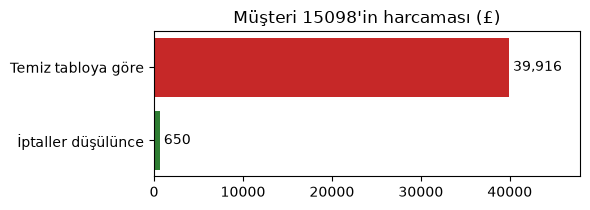

In [24]:
df_temiz = df_temiz.assign(Tutar=df_temiz["Quantity"] * df_temiz["Price"])
ham_tutar = df["Quantity"] * df["Price"]

temizde = df_temiz.loc[df_temiz["Customer ID"] == 15098, "Tutar"].sum()
gercekte = ham_tutar[df["Customer ID"] == 15098].sum()   # iptaller eksi olduğu için kendiliğinden düşülür
print(f"Temiz tabloya göre harcama : {temizde:>10,.2f} £")
print(f"İptaller düşülünce         : {gercekte:>10,.2f} £")

fig, ax = plt.subplots(figsize=(6, 2.2))
ax.barh(["İptaller düşülünce", "Temiz tabloya göre"], [gercekte, temizde], color=[YESIL, KIRMIZI])
ax.set_title("Müşteri 15098'in harcaması (£)")
for i, v in enumerate([gercekte, temizde]):
    ax.text(v, i, f" {v:,.0f}", va="center")
ax.set_xlim(0, temizde * 1.2)
plt.tight_layout()
plt.show()

Temiz tablo bu müşteriyi **yaklaşık 40 bin sterlinlik** bir müşteri olarak görüyor; gerçekte harcadığı tutar **650 sterlin**. Tek bir müşteri için **60 kat** fark.

#### Bu hata yalnızca bir müşteriyi mi etkiliyor?
Hayır. Aynı şey verinin her yerinde oluyor: iptal satırı siliniyor, iptal edilen satış kalıyor. Bu durumun Hafta 5'te kurduğumuz **en çok satanlar** listesine etkisine bakalım. Her ürün için temiz tablodaki adedi ve **iptaller düşülünce** kalan adedi karşılaştıralım:

                                    temiz_tabloda  iptal_edilen  \
Description                                                       
PAPER CRAFT , LITTLE BIRDIE                 80995         80995   
MEDIUM CERAMIC TOP STORAGE JAR              78033         74494   
WORLD WAR 2 GLIDERS ASSTD DESIGNS           54951          1200   
JUMBO BAG RED RETROSPOT                     48371          1115   
WHITE HANGING HEART T-LIGHT HOLDER          37872          2578   

                                    iptaller_dusulunce  
Description                                             
PAPER CRAFT , LITTLE BIRDIE                          0  
MEDIUM CERAMIC TOP STORAGE JAR                    3539  
WORLD WAR 2 GLIDERS ASSTD DESIGNS                53751  
JUMBO BAG RED RETROSPOT                          47256  
WHITE HANGING HEART T-LIGHT HOLDER               35294  


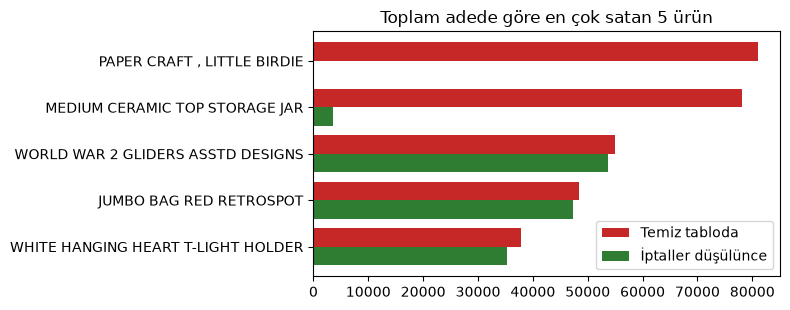

In [25]:
# İptal satırları (ürün kodlu olanlar); Quantity eksi, onu artıya çeviriyoruz
iptaller = df[df["Invoice"].str.startswith("C") & df["StockCode"].str[0].str.isdigit()]
iptal_adet = -iptaller.groupby("Description")["Quantity"].sum()

satis_adet = df_temiz.groupby("Description")["Quantity"].sum()
ilk5 = satis_adet.nlargest(5)

karsilastirma = pd.DataFrame({
    "temiz_tabloda": ilk5,
    "iptal_edilen": iptal_adet.reindex(ilk5.index).fillna(0).astype(int),
})
karsilastirma["iptaller_dusulunce"] = karsilastirma["temiz_tabloda"] - karsilastirma["iptal_edilen"]
print(karsilastirma)

fig, ax = plt.subplots(figsize=(8, 3.2))
y = range(len(karsilastirma))[::-1]
ax.barh([i + 0.2 for i in y], karsilastirma["temiz_tabloda"], height=0.4, color=KIRMIZI, label="Temiz tabloda")
ax.barh([i - 0.2 for i in y], karsilastirma["iptaller_dusulunce"], height=0.4, color=YESIL, label="İptaller düşülünce")
ax.set_yticks(list(y))
ax.set_yticklabels(karsilastirma.index)
ax.set_title("Toplam adede göre en çok satan 5 ürün")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Listenin ilk iki ürünü aslında hiç satılmamış ya da neredeyse hiç satılmamış.**
- **PAPER CRAFT, LITTLE BIRDIE:** 80.995 adetlik tek bir sipariş 12 dakika sonra **tamamen iptal edilmiş**. Gerçek satış: **0**.
- **MEDIUM CERAMIC TOP STORAGE JAR:** 74.215 adetlik sipariş 16 dakika sonra iptal edilmiş. Geriye kalan gerçek satışlar birkaç bin adet.

Hafta 5'te 4.3'teki **🕵️ İz sür** görevinde birinci sıradaki ürünün tuhaflığını konuşmuştuk. Bu, o tuhaflığın **nedeni**. Son olarak bütün veride ne kadar "hayalet satış" kaldığına bakalım:

In [26]:
iptal_tutar = -(iptaller["Quantity"] * iptaller["Price"]).sum()
print(f"İptal edilen adet / temiz tablodaki adet  : %{100 * -iptaller['Quantity'].sum() / df_temiz['Quantity'].sum():.1f}")
print(f"İptal edilen tutar / temiz tablodaki ciro : %{100 * iptal_tutar / df_temiz['Tutar'].sum():.1f}")

İptal edilen adet / temiz tablodaki adet  : %4.9
İptal edilen tutar / temiz tablodaki ciro : %4.7


<div style="background:#ffebee; color:#1a1a1a; border-left:6px solid #c62828; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#c62828; font-size:1.05em">📌 Asıl ders</b>

**Temizlik, bir satırı silmek değil, o satırın anlattığı olayı anlamaktır.**

Bir iptal satırı tek başına anlamlı değil: **başka bir satırı geçersiz kılıyor**. Biz iptal satırını sildik ama geçersiz kıldığı satışı tabloda bıraktık. Sonuçta temiz tablomuz **hiç gerçekleşmemiş satışları gerçekmiş gibi** gösteriyor:

| Neyi etkiledi? | Nasıl? |
|---|---|
| **En çok satanlar listesi** (Bölüm 4.2) | İlk iki ürün iptal edilmiş siparişler yüzünden orada |
| **Müşteri değeri** | 650 £ harcayan müşteri 40 bin £'lik müşteri gibi görünüyor |
| **Toplam ciro** | Yaklaşık **%5** şişkin |

Hata **sessiz**: Kod çalışıyor, sonuç makul görünüyor, hiçbir uyarı yok. Ancak sonucu **sorgulayınca** ("birinci sıradaki ürün neden birinci?") ortaya çıkıyor.

</div>

<div style="background:#fff3e0; color:#1a1a1a; border-left:6px solid #ef6c00; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#ef6c00; font-size:1.05em">⚠️ Dikkat</b>

Bunu tam düzeltmek için her iptali **kendi satışıyla eşleştirmek** gerekir. Kolay bir iş değil: iptal bazen aynı adetle, bazen elle (`M`) ve tek tutar olarak yapılıyor. Bu derste o adımı yapmadık.

Daha basit bir seçenek: Ürün ya da müşteri bazında **toplam** istiyorsak, iptal satırlarını silmek yerine tabloda **eksi değerleriyle** bırakıp toplamak. Yukarıdaki "iptaller düşülünce" sütunu tam olarak bunu yaptı. Bu seçeneğin de bir bedeli var: tek tek satırlarla çalışırken (örneğin sepet analizinde) eksi satırlar başka sorunlar çıkarır. Hangisinin seçileceği **analizin amacına** bağlı.

</div>

> E2'deki en pahalı satır (`C556445`, 38.970) ile buradaki şüpheli satır **aynı olayın iki parçası**. E2 ile E4'ü birlikte sormamızın nedeni bu.

**🔁 Benzerini dene:** Grafikte birinci sıradaki ürünü (*PAPER CRAFT, LITTLE BIRDIE*) satın alan müşteri **16446**. Bu müşterinin ham verideki bütün satırlarını göster. Sipariş ile iptal arasında kaç dakika var?

In [27]:
# Kodunu buraya yaz

<details><summary>✅ Cevap</summary>

```python
ham = df[df["Customer ID"] == 16446][["Invoice", "Description", "Quantity", "InvoiceDate", "Price"]].copy()
ham["tur"] = ham["Invoice"].str.startswith("C").map({True: "🔴 iptal", False: "🟢 alım"})
ham["temiz_tabloda"] = ham.index.isin(df_temiz.index)
ham
```
Yalnızca ilk satırı yazmak da yeterli; son iki sütun karşılaştırmayı kolaylaştırıyor. Hücrenin **son satırı** `ham` olmalı ki tablo ekranda görünsün.
9 Aralık 2011 saat 09:15'te 80.995 adet sipariş verilmiş, **12 dakika sonra** (09:27) `C581484` ile aynı adette iptal edilmiş. Müşterinin bunun dışında yalnızca 18 Mayıs'ta iki ürünlük küçük bir alışverişi var. Temiz tablo bu müşteriyi **en çok harcayan müşterilerden biri** olarak gösteriyor.

</details>

### ⭐ E5
**Soru:** Hangi **ayda** en çok fatura kesilmiş? (İpucu: `df_temiz["InvoiceDate"].dt.month` her satırın ay numarasını verir; `groupby`'a sütun adı yerine bunu verebilirsin.)

🕵️ Sonra veri hangi tarihler arasında, kontrol et (`.min()`, `.max()`). Aralık (12. ay) sonucuna güvenebilir miyiz?

In [28]:
ay = df_temiz["InvoiceDate"].dt.month
fatura_ay = df_temiz.groupby(ay)["Invoice"].nunique()
print(fatura_ay)
print("\nEn çok fatura kesilen ay:", fatura_ay.idxmax())

InvoiceDate
1     1081
2     1093
3     1440
4     1235
5     1668
6     1525
7     1452
8     1339
9     1818
10    2005
11    2751
12    2366
Name: Invoice, dtype: int64

En çok fatura kesilen ay: 11


**Kod ne yapıyor?**
- `df_temiz["InvoiceDate"].dt.month` her satırın **ay numarasını** (1–12) verir. `.dt` tarih sütunlarına özel araçları açar; `.str`'nin metinler için yaptığını tarihler için yapar.
- `groupby(ay)`: satırları bu ay numarasına göre gruplar. `groupby`'a bir sütun adı yerine **aynı uzunlukta bir Series** de verebiliriz.
- `["Invoice"].nunique()`: her gruptaki **farklı** fatura sayısı. `count()` ya da `size()` kullansaydık **satır** sayardık; bir fatura birçok satır tuttuğu için (B2) sonuç çok farklı olurdu.
- `.idxmax()`: en büyük değerin **index'ini** (burada ay numarasını) verir. `.max()` ise değerin kendisini verirdi.

**İlk bakışta:** En çok fatura **Kasım**'da (11. ay) kesilmiş. Sonbaharda bir artış var; yılbaşı alışverişi için mantıklı. Şimdi tarih aralığını kontrol edelim:

In [29]:
print("İlk tarih:", df_temiz["InvoiceDate"].min())
print("Son tarih:", df_temiz["InvoiceDate"].max())

İlk tarih: 2010-12-01 08:26:00
Son tarih: 2011-12-09 12:50:00


**Aralık sonucuna güvenebilir miyiz? Hayır.** Veri **1 Aralık 2010**'da başlıyor, **9 Aralık 2011**'de bitiyor. Yani "12. ay" satırında iki farklı şey **toplanmış**:
- Aralık 2010'un **tamamı** (31 gün),
- Aralık 2011'in yalnızca **ilk 9 günü**.

`dt.month` yalnızca ay numarasına bakar, **yılı görmez**. Doğrusu, **yıl ve ayı birlikte** kullanmak:

InvoiceDate
2010-12    1550
2011-01    1081
2011-02    1093
2011-03    1440
2011-04    1235
2011-05    1668
2011-06    1525
2011-07    1452
2011-08    1339
2011-09    1818
2011-10    2005
2011-11    2751
2011-12     816
Freq: M, Name: Invoice, dtype: int64


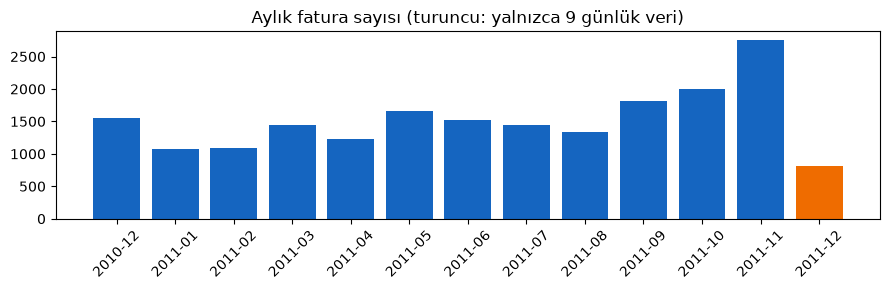

In [30]:
yil_ay = df_temiz["InvoiceDate"].dt.to_period("M")
fatura_yil_ay = df_temiz.groupby(yil_ay)["Invoice"].nunique()
print(fatura_yil_ay)

renkler = [TURUNCU if str(p) == "2011-12" else MAVI for p in fatura_yil_ay.index]
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(fatura_yil_ay.index.astype(str), fatura_yil_ay.values, color=renkler)
ax.set_title("Aylık fatura sayısı (turuncu: yalnızca 9 günlük veri)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

`.dt.to_period("M")` her tarihi **yıl-ay** biçimine (örneğin `2011-11`) çevirir. Artık 13 ayrı grup var. **2011-12** yalnızca 9 günlük veri olduğu için çok düşük görünüyor; **2010-12** ise tam bir ay.

<div style="background:#e8f5e9; color:#1a1a1a; border-left:6px solid #2e7d32; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#2e7d32; font-size:1.05em">🎯 Ne elde ettik?</b>

- En yoğun ay **Kasım 2011**; sonbaharda belirgin bir artış var.
- `dt.month` yılları birleştirdiği için "Aralık" satırı **iki yılın karışımıydı**.
- Grafikteki turuncu çubuk bir "düşüş" değil, **eksik veri**: kayıtlar 9 Aralık'ta bitiyor.

</div>

<div style="background:#fff3e0; color:#1a1a1a; border-left:6px solid #ef6c00; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#ef6c00; font-size:1.05em">⚠️ Dikkat</b>

Bir sonucu yorumlamadan önce verinin **hangi tarih aralığını kapsadığını** kontrol et. Eksik kalan bir dönem, gerçekte olmayan bir düşüşü ya da artışı gerçekmiş gibi gösterebilir.

</div>

**🔁 Benzerini dene:** Haftanın hangi **gününde** en çok fatura kesilmiş? (İpucu: `.dt.dayofweek` → 0 = Pazartesi, 6 = Pazar.) Sonuçta tuhaf bir şey var mı?

In [31]:
# Kodunu buraya yaz

<details><summary>✅ Cevap</summary>

```python
gun = df_temiz["InvoiceDate"].dt.dayofweek
df_temiz.groupby(gun)["Invoice"].nunique()
```
Sonuçta **5 (Cumartesi) yok**: mağaza o gün hiç fatura kesmemiş. Olmayan bir grup `groupby` sonucunda **0 olarak değil, hiç görünmez**. Bu yüzden bir değerin eksik olup olmadığını ancak dikkatle bakarak fark ederiz.

</details>

---
## Bölüm 4'ün ek alıştırmaları (temiz veri: `df_temiz`)

### ⭐ E6
**Soru:** Bir müşteri ortalama kaç farklı fatura kesmiş? (Müşteriye göre grupla, faturaları say, ortalamasını al.)

In [32]:
fatura_musteri = df_temiz.groupby("Customer ID")["Invoice"].nunique()
print("Müşteri sayısı :", len(fatura_musteri))
print("Ortalama       :", round(fatura_musteri.mean(), 2))
print("Medyan         :", fatura_musteri.median())
print("En çok         :", fatura_musteri.max())

Müşteri sayısı : 4334
Ortalama       : 4.25
Medyan         : 2.0
En çok         : 206


**Kod ne yapıyor?** Soruda tarif edilen üç adım, sırayla zincir hâlinde:
1. `groupby("Customer ID")`: satırları müşteriye göre grupla,
2. `["Invoice"].nunique()`: her müşterinin **farklı** fatura sayısını bul,
3. `.mean()`: bu sayıların ortalamasını al.

Sonucu önce `fatura_musteri` adlı bir değişkene aldık; böylece aynı Series'ten ortalama, medyan ve en büyük değeri ayrı ayrı okuyabildik.

**Sonucu nasıl okumalı?**
Bir müşteri **ortalama 4,25** fatura kesmiş, ama **medyan 2**. Ortalama medyandan çok büyük: dağılım **sağa çarpık**. Müşterilerin yarısı en fazla 2 kez alışveriş yapmış; birkaç müşteri ise (en çok 206 fatura) ortalamayı yukarı çekiyor. Seviye testindeki "100, 120, 110, 90, 5000" sorusunun gerçek veride karşılığı bu.

<div style="background:#fff3e0; color:#1a1a1a; border-left:6px solid #ef6c00; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#ef6c00; font-size:1.05em">⚠️ Dikkat</b>

`groupby`, müşteri numarası **boş** olan satırları kendiliğinden dışarıda bırakır. Yani bu hesap yalnızca numarası bilinen müşterileri kapsıyor. `Customer ID` sütununun dörtte birine yakını boştu; o satışlar bu ortalamada **yok**. Hiçbir uyarı da vermez: bunu bilmen gerekir.

</div>

<div style="background:#e8f5e9; color:#1a1a1a; border-left:6px solid #2e7d32; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#2e7d32; font-size:1.05em">🎯 Ne elde ettik?</b>

- Çarpık dağılımda **ortalama yanıltır**; tipik müşteriyi **medyan** daha iyi anlatır.
- Müşterilerin çoğunun geçmişi **çok kısa** (1–2 fatura). Kişiye özel öneri için elimizde az bilgi var. En çok satanlar listesinin bu müşteriler için hâlâ gerekli olmasının nedeni bu.

</div>

**🔁 Benzerini dene:** Yalnızca **bir kez** alışveriş yapan müşterilerin oranı ne?

In [33]:
# Kodunu buraya yaz

<details><summary>✅ Cevap</summary>

```python
(fatura_musteri == 1).mean()
```
Yaklaşık **%35**. `fatura_musteri == 1` bir maske üretir; `.mean()` `True` oranını verir. Her üç müşteriden biri bir daha gelmemiş.

</details>

### ⭐ E7
**Soru:** Her ülkede kaç farklı müşteri var? En çok müşterisi olan 5 ülke? İngiltere dışındaki ülkeler için "ülkeye göre en çok satan" listesine ne kadar güvenebiliriz?

In [34]:
musteri_ulke = df_temiz.groupby("Country")["Customer ID"].nunique()
musteri_ulke.sort_values(ascending=False).head()

Country
United Kingdom    3916
Germany             94
France              87
Spain               30
Belgium             25
Name: Customer ID, dtype: int64

**Kod ne yapıyor?**
- `groupby("Country")["Customer ID"].nunique()`: her ülkedeki **farklı** müşteri sayısı. (`nunique` boş değerleri saymaz.)
- `.sort_values(ascending=False)`: büyükten küçüğe sırala; `.head()` ilk 5'i göster.
- Aynı işi `musteri_ulke.nlargest(5)` tek adımda yapar.

**Sonucu nasıl okumalı?**
İngiltere'de **3.916** müşteri var. İkinci sıradaki Almanya'da **94**, üçüncü sıradaki Fransa'da **87**; beşinci sıradaki Belçika'da yalnızca **25**. Bütün ülkeleri bir grafikte görelim:

Ülke sayısı                : 38
5 ya da daha az müşterili  : 19


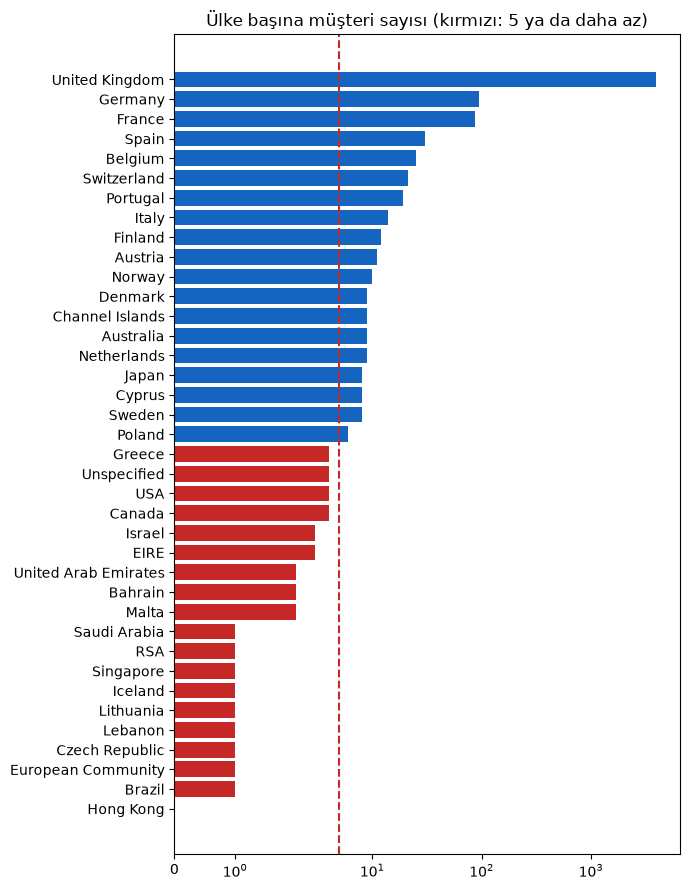

In [35]:
print("Ülke sayısı                :", len(musteri_ulke))
print("5 ya da daha az müşterili  :", (musteri_ulke <= 5).sum())

sirali = musteri_ulke.sort_values()
renkler = [KIRMIZI if v <= 5 else MAVI for v in sirali.values]
fig, ax = plt.subplots(figsize=(7, 9))
ax.barh(sirali.index, sirali.values, color=renkler)
ax.set_xscale("symlog")   # 0 değerini de gösterebilen log ölçek
ax.axvline(5, color=KIRMIZI, linestyle="--")
ax.set_title("Ülke başına müşteri sayısı (kırmızı: 5 ya da daha az)")
plt.tight_layout()
plt.show()

Ülkelerin yaklaşık **yarısında 5 ya da daha az** müşteri var; birçoğunda yalnızca **1**. Hong Kong'da ise **0** görünüyor: bu ülkeden satış var, ama satırların hiçbirinde müşteri numarası yok. `nunique` boş değerleri saymadığı için sonuç 0 çıkıyor.

**Güvenebilir miyiz?** İngiltere dışındaki çoğu ülke için **hayır**. Müşterisi 1–5 kişi olan bir ülkede "en çok satanlar" listesi, aslında o birkaç kişinin **kendi zevkini** gösterir; ülkenin genel eğilimini değil. Tek bir toptancı müşteri bütün listeyi belirleyebilir. Almanya ve Fransa gibi birkaç ülkede liste anlamlı olabilir, ama İngiltere'ye göre yine çok daha az veriye dayanır.

<div style="background:#e8f5e9; color:#1a1a1a; border-left:6px solid #2e7d32; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#2e7d32; font-size:1.05em">🎯 Ne elde ettik?</b>

- Müşterilerin **%90'dan fazlası** İngiltere'de.
- Grafikteki kırmızı çubukların her biri, "ülkeye göre en çok satan" listesinin **birkaç kişinin zevkinden** ibaret olduğu bir ülke.

</div>

<div style="background:#f3e5f5; color:#1a1a1a; border-left:6px solid #6a1b9a; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#6a1b9a; font-size:1.05em">🧭 Karar senin</b>

**Ne kadar veri "yeterli"?**

Bölüm 4.5'te verisi **hiç** olmayan ülke için mağazanın genel listesine dönmüştük (soğuk başlangıç). Verisi **çok az** olan ülke için de aynı karar gerekiyor:

> Bir **eşik** koyarız. Ülkedeki müşteri sayısı eşiğin altındaysa **genel listeyi**, üstündeyse **ülke listesini** gösteririz.

Eşik 5 mi olmalı, 20 mi, 50 mi? **Bu sayı veriden çıkmaz; analistin vereceği bir karardır.** Eşik düşük olursa birkaç kişinin zevkine dayanan listeler gösterilir. Eşik yüksek olursa ülkeye özgü gerçek farklar kaybolur.

Bu ders boyunca sık sık karşılaşacağın bir durum: **Kod her eşikle çalışır. Hangi eşiğin doğru olduğuna sen karar verirsin ve kararını gerekçelendirirsin.** Yapay zekâ araçları kodu yazabilir; bu kararı senin yerine veremez.

</div>

**🔁 Benzerini dene:** Her ülkede kaç farklı **fatura** var? Müşteri sayısına göre sıralamayla aynı mı?

In [36]:
# Kodunu buraya yaz

<details><summary>✅ Cevap</summary>

```python
df_temiz.groupby("Country")["Invoice"].nunique().nlargest(5)
```
İlk üç sıra aynı (İngiltere, Almanya, Fransa), ama dördüncü sırada **EIRE** (İrlanda) var. İrlanda'da yalnızca **3** müşteri var; bu üç müşteri çok sık alışveriş yaptığı için fatura sayısında Belçika'nın bile önüne geçiyor. Müşteri sayısına göre İspanya dördüncüydü. Hangi ölçüyle sıraladığın sonucu değiştirir: Bölüm 4.4'teki dersin aynısı.

</details>

### ⭐ E8
**Soru:** Bir sepette (faturada) ortalama kaç **farklı ürün** var? Ortalama ile medyanı karşılaştır. (Gelecek haftanın sepet analizi bu sayıya çok bağlı.)

In [37]:
sepet_buyuklugu = df_temiz.groupby("Invoice")["StockCode"].nunique()
print("Sepet sayısı :", len(sepet_buyuklugu))
print("Ortalama     :", round(sepet_buyuklugu.mean(), 1))
print("Medyan       :", sepet_buyuklugu.median())

Sepet sayısı : 19773
Ortalama     : 26.2
Medyan       : 15.0


**Kod ne yapıyor?**
- `groupby("Invoice")`: her fatura bir **sepet**; satırları faturaya göre grupla.
- `["StockCode"].nunique()`: her sepetteki **farklı** ürün sayısı. Burada `nunique` önemli: bir ürün aynı faturada iki ayrı satırda geçebilir; `count()` onu iki kez sayardı.

**Sonucu nasıl okumalı?**
Bir sepette **ortalama 26** farklı ürün var, ama **medyan 15**. E6'daki gibi ortalama medyandan büyük: birkaç çok büyük sepet ortalamayı yukarı çekiyor. Dağılımı görelim:

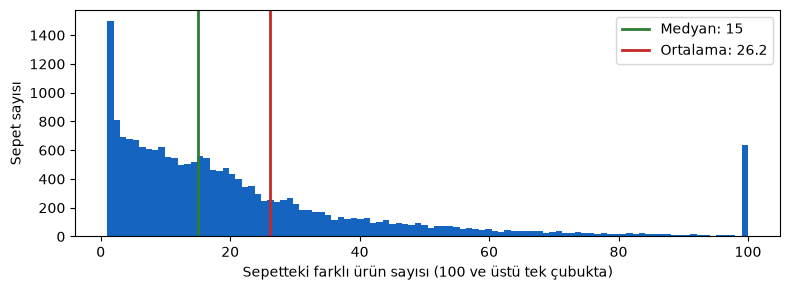

Sepetlerin %50'si en fazla 15.0 ürün içeriyor
Sepetlerin %90'ı en fazla  52.0 ürün içeriyor
Sepetlerin %99'u en fazla  218.0 ürün içeriyor
En büyük sepet            : 1108 farklı ürün


In [38]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(sepet_buyuklugu.clip(upper=100), bins=100, color=MAVI)
ax.axvline(sepet_buyuklugu.median(), color=YESIL, linewidth=2, label=f"Medyan: {sepet_buyuklugu.median():.0f}")
ax.axvline(sepet_buyuklugu.mean(), color=KIRMIZI, linewidth=2, label=f"Ortalama: {sepet_buyuklugu.mean():.1f}")
ax.set_xlabel("Sepetteki farklı ürün sayısı (100 ve üstü tek çubukta)")
ax.set_ylabel("Sepet sayısı")
ax.legend()
plt.tight_layout()
plt.show()

print("Sepetlerin %50'si en fazla", sepet_buyuklugu.quantile(0.50), "ürün içeriyor")
print("Sepetlerin %90'ı en fazla ", sepet_buyuklugu.quantile(0.90), "ürün içeriyor")
print("Sepetlerin %99'u en fazla ", sepet_buyuklugu.quantile(0.99), "ürün içeriyor")
print("En büyük sepet            :", sepet_buyuklugu.max(), "farklı ürün")

Grafiğin sağ ucundaki uzun kuyruk ve 100'deki tek çubuk, çok büyük sepetlerin varlığını gösteriyor. Bu veri bir **toptancının** verisi; sıradan bir markette sepetler çok daha küçük olurdu.

Gelecek haftanın sepet analizi için **iki uç** önemli. Önce küçük uç:

In [39]:
print("Tek ürünlü sepet sayısı :", (sepet_buyuklugu == 1).sum())
print("Tek ürünlü sepet oranı  :", round((sepet_buyuklugu == 1).mean(), 3))

Tek ürünlü sepet sayısı : 1500
Tek ürünlü sepet oranı  : 0.076


**Tek ürünlü sepetler** (yaklaşık %8) sepet analizine hiçbir şey katmaz: "bunu alan şunu da aldı" diyebilmek için sepette **en az iki** ürün gerekir.

#### Büyük uç: sepetler eşit ağırlıkta değil
Sepet analizi **ürün çiftlerine** bakar: "A ile B aynı sepette mi?" İçinde *n* farklı ürün olan bir sepet **n × (n − 1) / 2** çift üretir:

| Sepetteki ürün | Ürettiği çift |
|---|---|
| 2 | 1 |
| 10 | 45 |
| 50 | 1.225 |
| 1.108 | 613.278 |

Yani en büyük sepet tek başına, 2 ürünlü 613 bin sepet kadar çift üretiyor. Bütün veride bunun etkisini ölçelim:

50'den fazla ürünlü sepetlerin, sepetler içindeki payı : %11
Bu sepetlerin, bütün ürün çiftleri içindeki payı       : %88


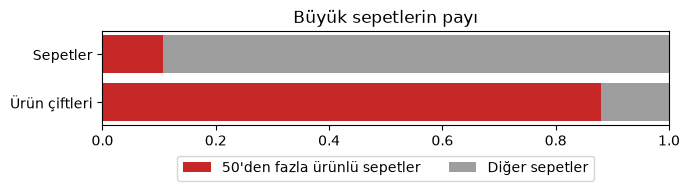

In [40]:
cift_sayisi = sepet_buyuklugu * (sepet_buyuklugu - 1) / 2
buyuk = sepet_buyuklugu > 50

print(f"50'den fazla ürünlü sepetlerin, sepetler içindeki payı : %{100 * buyuk.mean():.0f}")
print(f"Bu sepetlerin, bütün ürün çiftleri içindeki payı       : %{100 * cift_sayisi[buyuk].sum() / cift_sayisi.sum():.0f}")

fig, ax = plt.subplots(figsize=(7, 2.2))
paylar = [buyuk.mean(), cift_sayisi[buyuk].sum() / cift_sayisi.sum()]
ax.barh(["Ürün çiftleri", "Sepetler"], [paylar[1], paylar[0]], color=KIRMIZI, label="50'den fazla ürünlü sepetler")
ax.barh(["Ürün çiftleri", "Sepetler"], [1 - paylar[1], 1 - paylar[0]],
        left=[paylar[1], paylar[0]], color=GRI, label="Diğer sepetler")
ax.set_xlim(0, 1)
ax.set_title("Büyük sepetlerin payı")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2)
plt.tight_layout()
plt.show()

Sepetlerin yalnızca **onda biri**, bütün ürün çiftlerinin **yaklaşık %88'ini** üretiyor. Gelecek hafta "hangi ürünler birlikte alınıyor?" diye sorduğumuzda, cevabı büyük ölçüde bu az sayıdaki büyük sepet belirleyecek.

#### Büyük sepetleri kimler dolduruyor?

In [41]:
musterisiz = df_temiz.groupby("Invoice")["Customer ID"].first().isnull()
print(f"Müşteri numarası boş olanların oranı, 50'den fazla ürünlü sepetlerde : %{100 * musterisiz[buyuk].mean():.1f}")
print(f"Müşteri numarası boş olanların oranı, diğer sepetlerde               : %{100 * musterisiz[~buyuk].mean():.1f}")
print()
print("En büyük 5 sepet:")
en_buyuk5 = sepet_buyuklugu.nlargest(5).index
print(df_temiz[df_temiz["Invoice"].isin(en_buyuk5)]
      .groupby("Invoice")
      .agg(urun=("StockCode", "nunique"), musteri=("Customer ID", "first"), tarih=("InvoiceDate", "first"))
      .sort_values("urun", ascending=False))

Müşteri numarası boş olanların oranı, 50'den fazla ürünlü sepetlerde : %28.2
Müşteri numarası boş olanların oranı, diğer sepetlerde               : %4.4

En büyük 5 sepet:
         urun  musteri               tarih
Invoice                                   
573585   1108      NaN 2011-10-31 14:41:00
581219    748      NaN 2011-12-08 09:28:00
581492    730      NaN 2011-12-09 10:03:00
580729    720      NaN 2011-12-05 17:24:00
558475    703      NaN 2011-06-29 15:58:00


Büyük sepetlerde müşteri numarası boş olma oranı, diğerlerinin **yaklaşık 6 katı**. En büyük 5 sepetin **hiçbirinde** müşteri numarası yok. Bu sepetlerin gerçekte ne olduğunu veriden kesin bilemeyiz: toptan bir sipariş, mağaza içi bir aktarım ya da birkaç siparişin tek faturada toplanması olabilir. Bildiğimiz şu: bunlar **sıradan bir müşterinin sepetine benzemiyor**.

<div style="background:#e8f5e9; color:#1a1a1a; border-left:6px solid #2e7d32; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#2e7d32; font-size:1.05em">🎯 Ne elde ettik?</b>

- Tipik sepet **15 ürün** (medyan); ortalama (26) büyük sepetler yüzünden yanıltıcı.
- **Küçük uç:** Tek ürünlü sepetler (~%8) sepet analizine bilgi katmaz.
- **Büyük uç:** 50'den fazla ürünlü sepetler sayıca %11, ama ürün çiftlerinin **%88'i** onlardan geliyor. Üstelik bunların önemli bir kısmının müşterisi belli değil.

</div>

<div style="background:#f3e5f5; color:#1a1a1a; border-left:6px solid #6a1b9a; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#6a1b9a; font-size:1.05em">🧭 Karar senin</b>

**Sepet analizine hangi sepetleri alalım?**

- Tek ürünlü sepetleri çıkarmak kolay bir karar: bilgi taşımıyorlar.
- Büyük sepetler için karar zor. Çıkarırsak gerçek toptancı alışkanlıklarını kaybedebiliriz. Bırakırsak sonuçlar az sayıda sıra dışı sepetin etkisinde kalır.
- Bir **üst sınır** koymak bir seçenek. Ama sınır 50 mi olmalı, 100 mü, 200 mü? E7'deki eşik gibi bu sayı da **veriden çıkmaz**.

Gelecek hafta sepet analizine geçerken bu soru yeniden önümüze çıkacak. Şimdiden düşün: **sen hangi sepetleri dışarıda bırakırdın ve neden?**

</div>

**🔁 Benzerini dene (1):** Sepetlerin yüzde kaçında **50'den fazla** farklı ürün var?

In [42]:
# Kodunu buraya yaz

<details><summary>✅ Cevap</summary>

```python
(sepet_buyuklugu > 50).mean()
```
Yaklaşık **%11**. Az gibi görünür, ama yukarıda gördüğün gibi ürün çiftlerinin %88'ini bu sepetler üretiyor.

</details>

**🔁 Benzerini dene (2):** Sepet analizine yalnızca **2 ile 50 arasında** ürün içeren sepetleri alsaydık kaç sepet kalırdı? Bütün sepetlerin yüzde kaçı eder? (İpucu: iki koşulu `&` ile birleştir ve her koşulu paranteze al.)

In [43]:
# Kodunu buraya yaz

<details><summary>✅ Cevap</summary>

```python
secilen = (sepet_buyuklugu >= 2) & (sepet_buyuklugu <= 50)
print(secilen.sum(), "sepet;", round(secilen.mean() * 100, 1), "%")
```
**16.177 sepet**, yani yaklaşık **%82**. Parantezler zorunlu: `&` işlemi `>=` ve `<=` karşılaştırmalarından **önce** yapılır. Hafta 5'teki 2.2 numaralı 🐞 hata avında karşılaştığın tuzağın aynısı.

</details>

---
## 📚 Başvuru: Bu defterde neyi nerede yaptık?
Bir şeyi "hoca bunu bir yerde yapmıştı" diye arıyorsan önce buraya bak. **Sol sütunda ne yapmak istediğini bul**, ortadaki kalıbı kendi verine uyarla, sağdaki yerde örneğini gör.

<table>
<tr style="background:#37474f; color:#ffffff"><th>Ne yapmak istiyorum?</th><th>Kod kalıbı</th><th>Nerede?</th></tr>

<tr style="background:#1565c0; color:#ffffff"><td colspan="3"><b>🔢 Saymak</b></td></tr>
<tr style="background:#e3f2fd; color:#1a1a1a"><td>Bir sütunda her değerden kaç tane var?</td><td><code>df["Country"].value_counts()</code></td><td>E1, B3</td></tr>
<tr style="background:#e3f2fd; color:#1a1a1a"><td>Kaç farklı değer var?</td><td><code>df["StockCode"].nunique()</code></td><td>E7, E8</td></tr>
<tr style="background:#e3f2fd; color:#1a1a1a"><td>Bir koşulu sağlayan kaç satır, yüzde kaç?</td><td><code>maske.sum()</code> · <code>maske.mean()</code></td><td>E3, E6, E8</td></tr>
<tr style="background:#e3f2fd; color:#1a1a1a"><td>İki koşulun birlikte görülme sayıları</td><td><code>pd.crosstab(maske1, maske2)</code></td><td>E3</td></tr>

<tr style="background:#2e7d32; color:#ffffff"><td colspan="3"><b>🔎 Seçmek ve süzmek</b></td></tr>
<tr style="background:#e8f5e9; color:#1a1a1a"><td>Koşula uyan satırlar</td><td><code>df[df["Customer ID"] == 15098]</code></td><td>E4</td></tr>
<tr style="background:#e8f5e9; color:#1a1a1a"><td>Koşula uyan satırların tek bir sütunu</td><td><code>df.loc[maske, "Price"]</code></td><td>E3</td></tr>
<tr style="background:#e8f5e9; color:#1a1a1a"><td>İki koşul birlikte</td><td><code>(s &gt;= 2) &amp; (s &lt;= 50)</code></td><td>E8</td></tr>
<tr style="background:#e8f5e9; color:#1a1a1a"><td>Metin şununla başlıyor mu?</td><td><code>df["Invoice"].str.startswith("C")</code></td><td>B3, E4</td></tr>
<tr style="background:#e8f5e9; color:#1a1a1a"><td>İlk karakter rakam mı?</td><td><code>df["StockCode"].str[0].str.isdigit()</code></td><td>B4, E2</td></tr>
<tr style="background:#e8f5e9; color:#1a1a1a"><td>Boş mu?</td><td><code>df["Description"].isnull()</code></td><td>E3</td></tr>
<tr style="background:#e8f5e9; color:#1a1a1a"><td>Belli değerlerden biri mi?</td><td><code>df["Invoice"].isin(liste)</code></td><td>E8</td></tr>
<tr style="background:#e8f5e9; color:#1a1a1a"><td>Bu satır temizlikten sonra kaldı mı?</td><td><code>ham.index.isin(df_temiz.index)</code></td><td>E4</td></tr>
<tr style="background:#e8f5e9; color:#1a1a1a"><td>Bir kod sütununun desenleri</td><td><code>.str.replace(r"[0-9]", "9", regex=True)</code> → <code>value_counts()</code></td><td>B4</td></tr>
<tr style="background:#e8f5e9; color:#1a1a1a"><td>Rastgele birkaç örnek</td><td><code>df["StockCode"].sample(12)</code></td><td>B4</td></tr>

<tr style="background:#ef6c00; color:#ffffff"><td colspan="3"><b>📊 Gruplamak</b></td></tr>
<tr style="background:#fff3e0; color:#1a1a1a"><td>Her grupta farklı değer sayısı</td><td><code>df.groupby("Invoice")["StockCode"].nunique()</code></td><td>E6, E7, E8</td></tr>
<tr style="background:#fff3e0; color:#1a1a1a"><td>Her grupta toplam</td><td><code>df.groupby("Description")["Quantity"].sum()</code></td><td>E4</td></tr>
<tr style="background:#fff3e0; color:#1a1a1a"><td>Bir grupta birden çok hesap</td><td><code>.agg(ad=("sütun", "işlem"), ...)</code></td><td>B4, E8</td></tr>
<tr style="background:#fff3e0; color:#1a1a1a"><td>İki tabloyu aynı index'e göre hizalamak</td><td><code>seri.reindex(index).fillna(0)</code></td><td>E4</td></tr>

<tr style="background:#6a1b9a; color:#ffffff"><td colspan="3"><b>📅 Tarihlerle çalışmak</b></td></tr>
<tr style="background:#f3e5f5; color:#1a1a1a"><td>Ay numarası (yılı görmez!)</td><td><code>df["InvoiceDate"].dt.month</code></td><td>E5</td></tr>
<tr style="background:#f3e5f5; color:#1a1a1a"><td>Yıl ve ay birlikte</td><td><code>df["InvoiceDate"].dt.to_period("M")</code></td><td>E5</td></tr>
<tr style="background:#f3e5f5; color:#1a1a1a"><td>Haftanın günü (0 = Pazartesi)</td><td><code>df["InvoiceDate"].dt.dayofweek</code></td><td>E5</td></tr>
<tr style="background:#f3e5f5; color:#1a1a1a"><td>Verinin tarih aralığı</td><td><code>.min()</code> · <code>.max()</code></td><td>E5</td></tr>

<tr style="background:#c62828; color:#ffffff"><td colspan="3"><b>📈 Uçlar, özetler ve sıralama</b></td></tr>
<tr style="background:#ffebee; color:#1a1a1a"><td>En büyük / en küçük n satır</td><td><code>df.nlargest(3, "Price")</code> · <code>nsmallest</code></td><td>E2, E4</td></tr>
<tr style="background:#ffebee; color:#1a1a1a"><td>Tipik değer ve dağılım</td><td><code>.median()</code> · <code>.describe()</code> · <code>.quantile(0.9)</code></td><td>E2, E6, E8</td></tr>
<tr style="background:#ffebee; color:#1a1a1a"><td>En büyük değerin etiketi</td><td><code>seri.idxmax()</code></td><td>E5</td></tr>
<tr style="background:#ffebee; color:#1a1a1a"><td>Sıraya göre okumak</td><td><code>seri.iloc[1:3]</code></td><td>E1</td></tr>

<tr style="background:#455a64; color:#ffffff"><td colspan="3"><b>🖼️ Grafik</b></td></tr>
<tr style="background:#eceff1; color:#1a1a1a"><td>Çubuk grafik (yatay / dikey)</td><td><code>ax.barh(...)</code> · <code>ax.bar(...)</code></td><td>B3, B4, E4, E7</td></tr>
<tr style="background:#eceff1; color:#1a1a1a"><td>Dağılım (histogram)</td><td><code>ax.hist(seri, bins=...)</code></td><td>E8</td></tr>
<tr style="background:#eceff1; color:#1a1a1a"><td>Çok farklı büyüklükleri aynı grafikte göstermek</td><td><code>ax.set_yscale("log")</code></td><td>B3, B4, E7</td></tr>
</table>

## 🧠 Veriden öğrendiklerimiz

<div style="background:#e8f5e9; color:#1a1a1a; border-left:6px solid #2e7d32; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#2e7d32; font-size:1.05em">🎯 Veriyi tanımak</b>

| | Ders | Nerede? |
|---|---|---|
| 1 | **Önce belgeyi oku, sonra veride sına.** Belgede olmayanı satırları okuyarak anla. Kod sütunlarında desen maskesi kullan; rastgele örneğe güvenme. | B1–B4 |
| 2 | **Satır ≠ sipariş ≠ müşteri.** Neyi saydığına dikkat et. | B2, E1, E5 |
| 3 | **Uç değerin başka neresi tuhaf?** Tek işaret yetmez; işaretler birleşince sonuca güvenebilirsin. | E2, E3 |
| 4 | **Çıkarım ile kesin bilgiyi ayır.** "Büyük olasılıkla" demek kanıtın gücünü doğru aktarır. | E3, E8 |

</div>

<div style="background:#ffebee; color:#1a1a1a; border-left:6px solid #c62828; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#c62828; font-size:1.05em">📌 Temizlik ve sessiz hatalar</b>

| | Ders | Nerede? |
|---|---|---|
| 5 | **Temizlik, olayı anlamaktır.** İptali silip iptal edilen satışı bırakırsak, gerçekleşmemiş satışlar sonuçlara karışır. | E4 |
| 6 | **Her kuralın bir yan etkisi var.** Bilerek kabul et. | B4, E3 |
| 7 | **Sessiz hatalar uyarı vermez.** `groupby`'ın boş değerleri atması, `dt.month`'un yılları birleştirmesi, olmayan grubun hiç görünmemesi. | E5, E6 |

</div>

<div style="background:#f3e5f5; color:#1a1a1a; border-left:6px solid #6a1b9a; padding:10px 16px; border-radius:6px; margin:8px 0">

<b style="color:#6a1b9a; font-size:1.05em">🧭 Öneri sistemine taşınacak kararlar</b>

| | Ders | Nerede? |
|---|---|---|
| 8 | **Çarpık dağılımda ortalama yanıltır.** Tipik değeri medyan anlatır. | E6, E8 |
| 9 | **Az veriye dayanan liste güvenilmez.** Eşiği veri değil, analist belirler. | E7 |
| 10 | **Sepetler eşit ağırlıkta değil.** Az sayıda büyük sepet, ürün çiftlerinin çoğunu üretir. | E8 |

</div>

**Gelecek hafta:** Bu sepetlerden "bunu alan şunu da aldı" kurallarını çıkaracağız. E4'teki hayalet satışlar ve E8'deki büyük sepetler, o kuralları doğrudan etkileyecek.